# Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** *¿Pueden convertir titulares peruanos en un clasificador de noticias?*

Se comparan tres formas de clasificar los titulares de `datos/noticias.csv` (La República + El Comercio):

| Enfoque | Qué es | Entrenamiento |
| :--- | :--- | :--- |
| **Zero-shot** | Un modelo de inferencia en lenguaje natural (NLI) decide qué categoría "se deduce" del titular | Ninguno: es el piso a superar |
| **LLM débil** | Gemini etiqueta el dataset completo con un prompt estructurado | Ninguno, pero cuesta llamadas a una API |
| **Fine-tuned** | DistilBERT multilingual ajustado con nuestros titulares | 3 épocas en CPU |

**Decisiones de diseño:**

1. **El split va primero.** Todas las comparaciones se hacen sobre el mismo conjunto de test, que no se usa para
   nada más hasta la evaluación final.
2. **La etiqueta de referencia es la editorial** (`etiqueta`, que sale de la sección donde el diario publicó la
   nota). El LLM es otro "anotador" que se evalúa contra ella.
3. **El clasificador se entrena solo con el titular**, porque en el dashboard el usuario escribe solo un titular:
   el texto de entrenamiento y el de uso tienen que parecerse.

In [1]:
import gc
import json
import os
import time
from datetime import date
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns
from dotenv import load_dotenv
from IPython.display import display
from pydantic import BaseModel, Field
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width, pio.renderers["png"].height = 950, 500
pd.set_option("display.max_colwidth", 110)

SEED = 42
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
DATOS, MODELO = Path("datos"), Path("modelo")

df = pd.read_csv(DATOS / "noticias.csv")
print("Dataset:", df.shape)
display(pd.crosstab(df["medio"], df["etiqueta"], margins=True, margins_name="Total"))

Dataset: (444, 7)


etiqueta,ciencia_tecnologia,deportes,economia,politica,Total
medio,,,,,
El Comercio,56,59,52,58,225
La Republica,60,52,47,60,219
Total,116,111,99,118,444


## 1. Partición 70 / 15 / 15

Split estratificado con `random_state=42`. Se estratifica por **medio + etiqueta** (no solo por etiqueta) para que
train, validación y test tengan la misma mezcla de La República y El Comercio en cada categoría. Así se puede medir
después si el modelo funciona igual de bien con ambos medios.

In [2]:
estrato = df["medio"] + " | " + df["etiqueta"]
train, temp = train_test_split(df, test_size=0.30, stratify=estrato, random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, stratify=estrato.loc[temp.index], random_state=SEED)

assert set(train["url"]).isdisjoint(val["url"])
assert set(train["url"]).isdisjoint(test["url"])
assert set(val["url"]).isdisjoint(test["url"])

particion = pd.concat([train.assign(particion="train"), val.assign(particion="val"),
                       test.assign(particion="test")])
particion[["url", "particion"]].to_csv(DATOS / "split.csv", index=False)
print({nombre: len(parte) for nombre, parte in [("train", train), ("val", val), ("test", test)]})
display(pd.crosstab(particion["particion"], [particion["medio"], particion["etiqueta"]]))

{'train': 310, 'val': 67, 'test': 67}


medio            El Comercio                                  La Republica  \
etiqueta  ciencia_tecnologia deportes economia politica ciencia_tecnologia   
particion                                                                    
test                       9        9        8        8                  9   
train                     39       41       36       41                 42   
val                        8        9        8        9                  9   

medio                                 
etiqueta  deportes economia politica  
particion                             
test             8        7        9  
train           36       33       42  
val              8        7        9

## 2. Línea base zero-shot (sin fine-tuning)

Se usa `Recognai/bert-base-spanish-wwm-cased-xnli`, un BERT en español entrenado para inferencia en lenguaje natural.
Para cada titular, el modelo evalúa la hipótesis *"Esta noticia trata sobre {categoría}."* con cada una de las 4
categorías y elige la más probable.

* Las categorías se le pasan **en español natural** ("ciencia y tecnología", no `ciencia_tecnologia`): el modelo
  entiende palabras, no códigos.
* Se evalúan **40 titulares del test** (10 por categoría). Es el piso mínimo que los otros enfoques deben superar.

In [3]:
from transformers import pipeline

ETIQUETA_NATURAL = {"politica": "política", "economia": "economía", "deportes": "deportes",
                    "ciencia_tecnologia": "ciencia y tecnología"}
NATURAL_A_CODIGO = {v: k for k, v in ETIQUETA_NATURAL.items()}

muestra_40 = test.groupby("etiqueta").sample(n=10, random_state=SEED)
zero_shot = pipeline("zero-shot-classification", model="Recognai/bert-base-spanish-wwm-cased-xnli",
                     device="cpu")

inicio = time.perf_counter()
salidas = zero_shot(muestra_40["titular"].tolist(), candidate_labels=list(ETIQUETA_NATURAL.values()),
                    hypothesis_template="Esta noticia trata sobre {}.")
latencia_zs = (time.perf_counter() - inicio) / len(muestra_40)
muestra_40["pred_zs"] = [NATURAL_A_CODIGO[s["labels"][0]] for s in salidas]

acc_zs = accuracy_score(muestra_40["etiqueta"], muestra_40["pred_zs"])
f1_zs = f1_score(muestra_40["etiqueta"], muestra_40["pred_zs"], average="macro")
print(f"ZERO-SHOT (40 titulares del test) | accuracy = {acc_zs:.3f} | F1 macro = {f1_zs:.3f} "
      f"| latencia = {latencia_zs * 1000:.0f} ms por titular")
display(pd.crosstab(muestra_40["etiqueta"], muestra_40["pred_zs"], rownames=["real"], colnames=["zero-shot"]))

del zero_shot, salidas      # se libera el modelo (~440 MB) antes del fine-tuning
gc.collect();

C:\Users\DOKU\Documents\GitHub\intermediate-python-hw\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 5431.67it/s]

ZERO-SHOT (40 titulares del test) | accuracy = 0.675 | F1 macro = 0.640 | latencia = 194 ms por titular


zero-shot,ciencia_tecnologia,deportes,economia,politica
real,,,,
ciencia_tecnologia,2,2,1,5
deportes,0,9,0,1
economia,0,1,7,2
politica,0,1,0,9


## 3. Supervisión débil con un LLM (Gemini)

El LLM etiqueta **el dataset completo** usando titular y bajada.

* **Prompt estructurado:** rol, definición de cada categoría y reglas para casos borde (ver `INSTRUCCIONES`).
* **Salida tipada:** `response_schema` obliga a Gemini a responder una lista JSON donde `etiqueta_llm` solo puede
  ser una de las 4 categorías (un `Literal`). No hace falta "limpiar" texto libre.
* **Lotes de 20 noticias** por llamada: 20 veces menos llamadas que de a una, menos costo y menos riesgo de
  chocar con el límite de peticiones por minuto del plan gratuito.
* **Robustez:** los alias `gemini-flash-latest` y `gemini-flash-lite-latest` siempre apuntan a la versión vigente
  (los modelos fechados se retiran). Ante un error (503 por saturación, 429 por cuota) se espera y se reintenta, y
  si un modelo falla se pasa al siguiente. La versión exacta que respondió queda en `modelo_llm`.
* **Caché incremental:** cada respuesta se agrega a `datos/raw/llm_respuestas.jsonl`. Si la ejecución se corta,
  se retoma donde quedó, y una vez completo el notebook se re-ejecuta **sin llamar a la API ni necesitar la clave**.
* La API key se lee de `tarea_1/.env` (`GEMINI_API_KEY`), que está en `.gitignore`.

> **Ojo con la "confianza":** es un número que el LLM *dice*, no una probabilidad calculada. En la sección 5 se
> verifica si está calibrada.

In [4]:
MODELOS_LLM = ["gemini-flash-latest", "gemini-flash-lite-latest"]
TAM_LOTE = 20
PAUSA_ENTRE_LOTES = 4          # segundos: respeta el límite de peticiones por minuto del plan gratuito
RUTA_CACHE_LLM = DATOS / "raw" / "llm_respuestas.jsonl"

INSTRUCCIONES = """Eres editor de un diario peruano. Clasifica cada noticia en UNA de estas 4 categorías:

- politica: Congreso, Poder Ejecutivo, ministros, partidos, elecciones y candidatos, autoridades regionales,
  política internacional, casos judiciales o de corrupción que involucran a políticos o funcionarios.
- economia: mercados, empresas, precios, inflación, tipo de cambio, empleo, impuestos, presupuesto público,
  comercio exterior, minería como actividad económica, AFP, bancos y finanzas personales.
- deportes: competencias, clubes, selecciones, atletas, resultados, fichajes, horarios y transmisiones de partidos.
- ciencia_tecnologia: investigación científica, espacio, salud y medicina como ciencia, medio ambiente y clima,
  tecnología, inteligencia artificial, internet, ciberseguridad, videojuegos.

Reglas:
1. Decide por el TEMA PRINCIPAL de la noticia, no por palabras sueltas.
2. Si una decisión política trata sobre un tema económico, mira qué destaca el titular: el proceso político
   (votación, conflicto entre poderes, autoridades) es politica; el impacto económico (montos, precios,
   afectados) es economia.
3. Usa el titular y la bajada.
4. confianza es tu probabilidad, entre 0 y 1, de que la etiqueta sea correcta.
Responde con un elemento por noticia, usando el mismo id que recibiste."""


class Clasificacion(BaseModel):
    id: int
    etiqueta_llm: Literal["politica", "economia", "deportes", "ciencia_tecnologia"]
    confianza: float = Field(ge=0, le=1)


def pedir_lote(cliente, lote):
    """Clasifica un lote (con columna id) y devuelve una fila por noticia; prueba los modelos en orden."""
    from google.genai import types

    texto = "\n".join(f"[{fila.id}] Titular: {fila.titular}\n     Bajada: {fila.bajada}"
                      for fila in lote.itertuples())
    config = types.GenerateContentConfig(
        system_instruction=INSTRUCCIONES, temperature=0,
        response_mime_type="application/json", response_schema=list[Clasificacion])
    for modelo in MODELOS_LLM:
        for intento in range(3):
            try:
                respuesta = cliente.models.generate_content(
                    model=modelo, contents=f"Clasifica estas {len(lote)} noticias:\n\n{texto}", config=config)
                filas = {c.id: c for c in respuesta.parsed}
                if set(lote["id"]) <= set(filas):
                    return [{**filas[i].model_dump(), "modelo_llm": respuesta.model_version or modelo}
                            for i in lote["id"]]
                print(f"    {modelo}: respuesta incompleta, se reintenta")
            except Exception as e:      # 503 (saturado), 429 (cuota) o una respuesta que no se pudo parsear
                espera = 10 * (intento + 1)
                print(f"    {modelo}: {type(e).__name__} → espera de {espera} s")
                time.sleep(espera)
    raise RuntimeError("Ningún modelo de MODELOS_LLM respondió; revisar la clave o la cuota")


cache_llm = {}
if RUTA_CACHE_LLM.exists():
    for linea in RUTA_CACHE_LLM.read_text(encoding="utf-8").splitlines():
        registro = json.loads(linea)
        cache_llm[registro["url"]] = registro

pendientes = df[~df["url"].isin(cache_llm)]
print(f"En caché: {len(cache_llm)} | por etiquetar: {len(pendientes)}")
if len(pendientes):
    from google import genai

    load_dotenv()
    cliente = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    for inicio in range(0, len(pendientes), TAM_LOTE):
        lote = pendientes.iloc[inicio:inicio + TAM_LOTE].reset_index(drop=True)
        lote["id"] = lote.index + 1
        t0 = time.perf_counter()
        filas = pedir_lote(cliente, lote)
        segundos = time.perf_counter() - t0
        with RUTA_CACHE_LLM.open("a", encoding="utf-8") as archivo:
            for fila, url in zip(filas, lote["url"]):
                registro = {"url": url, "etiqueta_llm": fila["etiqueta_llm"], "confianza": fila["confianza"],
                            "modelo_llm": fila["modelo_llm"], "fecha": date.today().isoformat(),
                            "segundos_por_noticia": segundos / len(lote)}
                cache_llm[url] = registro
                archivo.write(json.dumps(registro, ensure_ascii=False) + "\n")
        print(f"  lote {inicio // TAM_LOTE + 1}: {len(lote)} noticias en {segundos:.1f} s")
        time.sleep(PAUSA_ENTRE_LOTES)

# La caché puede guardar respuestas de notas que la limpieza descartó después (p. ej. tecnologia/streamers)
llm = pd.DataFrame(cache_llm.values())
llm = llm[llm["url"].isin(df["url"])]
df = df.merge(llm[["url", "etiqueta_llm", "confianza", "modelo_llm", "fecha"]].rename(columns={"fecha": "fecha_llm"}),
              on="url", validate="one_to_one")
assert len(df) == len(llm) and df["etiqueta_llm"].notna().all()

etiquetas_llm = (df[["titular", "etiqueta_llm", "confianza", "modelo_llm", "fecha_llm"]]
                 .rename(columns={"fecha_llm": "fecha"}))
etiquetas_llm.to_csv(DATOS / "etiquetas_llm.csv", index=False, encoding="utf-8")
latencia_llm = llm["segundos_por_noticia"].mean()
print(f"\nGuardado datos/etiquetas_llm.csv: {etiquetas_llm.shape} | modelos que respondieron: "
      f"{df['modelo_llm'].value_counts().to_dict()}")
display(etiquetas_llm.head())

En caché: 445 | por etiquetar: 0

Guardado datos/etiquetas_llm.csv: (444, 5) | modelos que respondieron: {'gemini-3.8-flash': 439, 'gemini-3.5-flash-lite': 5}


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,"“Grand Theft Auto VI” lanza un tráiler con una escena de sexo, la ocasión donde esto los metió en problemas",ciencia_tecnologia,0.95,gemini-3.8-flash,2026-10-17
1,"iPhone Duo se agota a minutos de abierta su preventa, ahora disponibles a partir del 22 de enero",ciencia_tecnologia,0.95,gemini-3.8-flash,2026-10-17
2,La IA ayuda a los historiadores a descifrar mensajes napoleónicos y papiros carbonizados,ciencia_tecnologia,0.98,gemini-3.8-flash,2026-10-17
3,"Efecto cine, batería de emergencia o verificación: cinco novedades del iPhone 18",ciencia_tecnologia,0.98,gemini-3.8-flash,2026-10-17
4,La alerta de seísmos de Google está disponible ya en 200 países de todo el mundo,ciencia_tecnologia,0.98,gemini-3.8-flash,2026-10-17


## 4. Auditoría humana a ciegas (20 casos)

Se eligen 20 noticias al azar (`random_state=42`) y se etiquetan **a mano, viendo solo el titular y la bajada**.
La plantilla `datos/auditoria_llm.csv` no muestra la etiqueta del LLM, ni la sección del diario, ni la URL (que
revela la sección): si quien audita ve la respuesta antes de decidir, se ancla a ella y el acuerdo sale inflado.

La auditoría tiene dos fases, en este orden:

1. **Etiquetar a ciegas** (`etiqueta_humana`): solo con titular y bajada.
2. **Verificar la extracción** (`extraccion_ok` = `si`/`no`): recién con las 20 etiquetas escritas, se abre la
   correspondencia `id → url` de `datos/raw/auditoria_claves.csv` y se comprueba en la web que el titular y la
   bajada coinciden con la nota publicada. Así se audita también el scraping sin contaminar la primera fase.

Después se comparan las etiquetas humanas con las del LLM.

**Hallazgo de la propia auditoría.** El caso 6 (*"¡Ya güey!: Edgar, niño cuya caída se convirtió en fenómeno viral
hace 20 años, se casa"*, de `tecnologia/streamers`) no encaja en ninguna de las 4 categorías. Siguiendo la consigna,
no se inventó una quinta: se agregó la regla de exclusión en la limpieza del notebook 01 y la nota salió del
dataset. Para mantener 20 casos válidos se sorteó un reemplazo (caso 21, `random_state=42` entre las noticias que
no estaban en la muestra), que también se etiquetó a ciegas.

In [5]:
RUTA_AUDITORIA = DATOS / "auditoria_llm.csv"
RUTA_CLAVES = DATOS / "raw" / "auditoria_claves.csv"

if not RUTA_AUDITORIA.exists():
    muestra = df.sample(20, random_state=SEED).reset_index(drop=True)
    muestra["id"] = muestra.index + 1
    muestra[["id", "url"]].to_csv(RUTA_CLAVES, index=False)
    (muestra[["id", "titular", "bajada"]].assign(etiqueta_humana="", extraccion_ok="", comentario="")
     .to_csv(RUTA_AUDITORIA, index=False, encoding="utf-8-sig"))
    raise SystemExit("Plantilla creada en datos/auditoria_llm.csv: completar etiqueta_humana y volver a ejecutar.")

auditoria = (pd.read_csv(RUTA_AUDITORIA, encoding="utf-8-sig").fillna({"comentario": ""})
             .merge(pd.read_csv(RUTA_CLAVES), on="id"))
fuera_de_dominio = auditoria[~auditoria["url"].isin(df["url"])]
print(f"Casos de la muestra descartados en la limpieza (fuera de las 4 categorías): {len(fuera_de_dominio)}")
display(fuera_de_dominio[["id", "titular", "comentario"]])
auditoria = auditoria.merge(df[["url", "etiqueta_llm", "confianza", "etiqueta"]], on="url")
assert len(auditoria) == 20, f"La auditoría debe tener 20 casos válidos y tiene {len(auditoria)}"
auditoria["etiqueta_humana"] = auditoria["etiqueta_humana"].str.strip()
auditoria["extraccion_ok"] = auditoria["extraccion_ok"].str.strip().str.lower()
assert auditoria["etiqueta_humana"].isin(CATEGORIAS).all(), "Hay etiquetas humanas vacías o mal escritas"
assert auditoria["extraccion_ok"].isin(["si", "no"]).all(), "extraccion_ok debe ser 'si' o 'no' en las 20 filas"

extraccion_ok = int((auditoria["extraccion_ok"] == "si").sum())
print(f"Extracción verificada contra la web: {extraccion_ok}/20 notas con titular y bajada correctos")
auditoria["acuerdo"] = auditoria["etiqueta_humana"] == auditoria["etiqueta_llm"]
acuerdo_llm_humano = int(auditoria["acuerdo"].sum())
print(f"Acuerdo LLM-humano: {acuerdo_llm_humano}/20 = {acuerdo_llm_humano / 20:.0%}")
display(auditoria[["id", "titular", "etiqueta_humana", "etiqueta_llm", "confianza", "acuerdo",
                   "extraccion_ok", "comentario"]])

Casos de la muestra descartados en la limpieza (fuera de las 4 categorías): 1


,id,titular,comentario
5,6,"¡Ya güey!: Edgar, niño cuya caída se convirtió en fenómeno viral hace 20 años, se casa",en realidad no encaja con ninguna etiqueta. Esto corresponderia a Entretenimiento o Espectaculo


Extracción verificada contra la web: 20/20 notas con titular y bajada correctos
Acuerdo LLM-humano: 19/20 = 95%


,id,titular,etiqueta_humana,etiqueta_llm,confianza,acuerdo,extraccion_ok,comentario
0,1,Científicos reconstruyen el rostro de un hombre que vivió en Ecuador hace 3.000 años y recrean su peinado ...,ciencia_tecnologia,ciencia_tecnologia,0.98,True,si,
1,2,"AFP: informalidad superior al 60% en ciudades del norte limita el alcance del nuevo retiro, advierte la CCL",economia,economia,0.95,True,si,
2,3,"El Perú podría producir 5,7 millones toneladas de cobre anualmente, pero, ¿qué falta para lograrlo?",economia,economia,0.98,True,si,
3,4,Las 12 reformas que necesita la Policía Nacional para vencer al crimen organizado,politica,politica,0.90,True,si,
4,5,¿Qué canal transmite Inter Miami vs. Atlanta United y a qué hora es el partido por MLS con Lionel Messi?,deportes,deportes,0.99,True,si,
5,7,Álvaro Vargas Llosa es nombrado embajador del Perú en EE.UU.: ¿Cuáles serán las prioridades de su agenda?,politica,politica,0.98,True,si,
6,8,¡Por primera vez en el Clausura! Piero Cari será convocado para el duelo de Alianza Lima ante Atlético Grau,deportes,deportes,0.99,True,si,
7,9,López Chau retoma propuesta de fondo soberano de riqueza para financiar la industrialización del Perú,economia,economia,0.88,True,si,
8,10,"Barcelona - Getafe: fecha, hora y canal del partido por la fecha 8 de LaLiga de España",deportes,deportes,0.99,True,si,
9,11,Noruega estudia prohibir temporalmente las gafas inteligentes,politica,ciencia_tecnologia,0.80,False,si,


## 5. ¿Coinciden el LLM y la etiqueta editorial?

La auditoría mide el acuerdo con una persona en 20 casos. Aquí se mide contra la etiqueta editorial en **todo el
dataset**. Los desacuerdos no siempre son errores del LLM: muchas son noticias ambiguas (una ley del Congreso sobre
las AFP es política y economía a la vez). También se revisa si la confianza que declara el LLM está calibrada.

Acuerdo LLM vs etiqueta editorial (dataset completo, 444 noticias): 95.7%


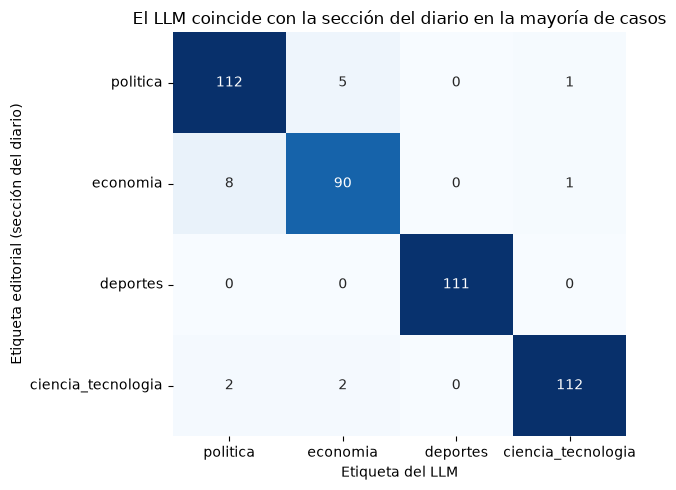

,noticias,confianza_media,acierto_real
tramo_confianza,,,
"(-0.001, 0.7]",2,0.700,1.000
"(0.7, 0.8]",11,0.791,0.727
"(0.8, 0.9]",47,0.877,0.745
"(0.9, 0.95]",55,0.944,0.945
"(0.95, 1.0]",329,0.986,0.997


Ejemplos de desacuerdo:


,medio,etiqueta,etiqueta_llm,confianza,titular
13,El Comercio,ciencia_tecnologia,economia,0.85,"Ventas de ‘smartphones’ registran una caída del 20%, motivado por la crisis de memoria RAM"
153,El Comercio,economia,politica,0.90,Mincetur designa a Roxana Barrantes como nuevo miembro del Consejo Directivo de Indecopi
352,La Republica,economia,politica,0.86,Adenda de Cálidda para llevar gas a siete regiones sigue en evaluación: Minem no confirma fecha de firma
21,El Comercio,ciencia_tecnologia,politica,0.80,El Niño en Perú: no está operativo ninguno de los 18 sistemas de alertas tempranas previstos desde 2017
202,El Comercio,politica,economia,0.90,Unión Europea y Minem acuerdan creación de mesa técnica para destrabar permisos e infraestructura
377,La Republica,economia,politica,0.93,"Minem entra en reorganización: Gobierno identifica fallas en inversiones, trámites y gestión de conflictos"
48,El Comercio,ciencia_tecnologia,politica,0.75,"EE.UU. ""sigue de cerca"" el caso de una técnica de laboratorio rusa que falleció en un centro de investigac..."
354,La Republica,economia,politica,0.88,Reinfo: formalización minera hasta 2028 exigirá cambios en el Estado y metas para los inscritos
376,La Republica,economia,politica,0.91,Petroperú: proyecto de JP busca impedir que sus activos pasen al régimen de inversión privada
396,La Republica,politica,ciencia_tecnologia,0.75,Papa León XIV últimas noticias: El Vaticano informa que el sumo pontífice pasó una noche tranquila


In [6]:
acuerdo_editorial = (df["etiqueta_llm"] == df["etiqueta"]).mean()
print(f"Acuerdo LLM vs etiqueta editorial (dataset completo, {len(df)} noticias): {acuerdo_editorial:.1%}")

matriz = pd.crosstab(df["etiqueta"], df["etiqueta_llm"]).reindex(index=CATEGORIAS, columns=CATEGORIAS, fill_value=0)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(xlabel="Etiqueta del LLM", ylabel="Etiqueta editorial (sección del diario)",
       title="El LLM coincide con la sección del diario en la mayoría de casos")
plt.tight_layout()
plt.show()

df["tramo_confianza"] = pd.cut(df["confianza"], bins=[0, 0.7, 0.8, 0.9, 0.95, 1.0], include_lowest=True)
calibracion = (df.assign(acierto=df["etiqueta_llm"] == df["etiqueta"])
                 .groupby("tramo_confianza", observed=True)
                 .agg(noticias=("acierto", "size"), confianza_media=("confianza", "mean"),
                      acierto_real=("acierto", "mean")).round(3))
display(calibracion)

print("Ejemplos de desacuerdo:")
display(df.loc[df["etiqueta_llm"] != df["etiqueta"], ["medio", "etiqueta", "etiqueta_llm", "confianza", "titular"]]
          .sample(min(10, int((df["etiqueta_llm"] != df["etiqueta"]).sum())), random_state=SEED))

## 6. Fine-tuning de DistilBERT

* **Modelo:** `distilbert-base-multilingual-cased`, una versión destilada de BERT multilingüe: 6 capas en lugar de 12,
  así que entrena e infiere rápido en CPU.
* **Entrada:** solo el titular, truncado a 64 tokens (de sobra para un titular).
* **Configuración:** 3 épocas, batch de 16, `learning_rate=5e-5`, evaluación en validación al final de cada época y
  se conserva la época con mejor **F1 macro** (`load_best_model_at_end`).
* **F1 macro** promedia el F1 de las 4 clases con el mismo peso: una categoría mal clasificada no se esconde detrás
  de las otras.
* **Experimento extra:** el mismo modelo entrenado con las etiquetas del LLM (`etiqueta_llm`) en lugar de las
  editoriales. Responde a la pregunta de la supervisión débil: ¿alcanzan las etiquetas de un LLM para entrenar un
  buen clasificador sin anotar nada a mano?

In [7]:
import tempfile

from datasets import Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, Trainer,
                          TrainingArguments, set_seed)

MODELO_BASE = "distilbert/distilbert-base-multilingual-cased"
LABEL2ID = {c: i for i, c in enumerate(CATEGORIAS)}
ID2LABEL = {i: c for c, i in LABEL2ID.items()}
tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)


def a_dataset(parte, columna_etiqueta):
    ds = Dataset.from_dict({"text": parte["titular"].tolist(),
                            "label": parte[columna_etiqueta].map(LABEL2ID).tolist()})
    return ds.map(lambda lote: tokenizer(lote["text"], truncation=True, max_length=64), batched=True)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1_macro": f1_score(labels, preds, average="macro")}


def entrenar(columna_etiqueta, carpeta):
    set_seed(SEED)
    modelo = AutoModelForSequenceClassification.from_pretrained(
        MODELO_BASE, num_labels=len(CATEGORIAS), id2label=ID2LABEL, label2id=LABEL2ID)
    args = TrainingArguments(
        output_dir=str(carpeta), num_train_epochs=3, per_device_train_batch_size=16,
        per_device_eval_batch_size=32, learning_rate=5e-5, weight_decay=0.01,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1_macro",
        logging_strategy="epoch", report_to="none", seed=SEED)
    trainer = Trainer(
        model=modelo, args=args, processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
        train_dataset=a_dataset(train, columna_etiqueta), eval_dataset=a_dataset(val, columna_etiqueta),
        compute_metrics=compute_metrics)
    inicio = time.perf_counter()
    trainer.train()
    print(f"Entrenamiento ({columna_etiqueta}) terminado en {time.perf_counter() - inicio:.0f} s")
    return trainer


# El split se hizo antes de unir las etiquetas del LLM: se recuperan por url
train, val, test = (parte[["url"]].merge(df, on="url") for parte in (train, val, test))

trainer = entrenar("etiqueta", MODELO)
historial = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
display(historial[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]].round(3))

trainer.save_model(str(MODELO))
tokenizer.save_pretrained(str(MODELO))
(MODELO / "label_map.json").write_text(json.dumps(ID2LABEL, indent=2), encoding="utf-8")
print("Modelo guardado en", MODELO)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 4254.94it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/310 [00:00<?, ? examples/s]

Map: 100%|██████████| 310/310 [00:00<00:00, 9393.26 examples/s]

...

,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.745,0.821,0.827
1,2.0,0.313,0.955,0.954
2,3.0,0.215,0.955,0.955


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.16it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.15it/s]

Modelo guardado en modelo


In [8]:
# Experimento extra: mismas condiciones, pero entrenado y validado con las etiquetas del LLM
with tempfile.TemporaryDirectory() as carpeta_tmp:
    trainer_llm = entrenar("etiqueta_llm", carpeta_tmp)
    pred_llm_ft = trainer_llm.predict(a_dataset(test, "etiqueta")).predictions.argmax(-1)
test["pred_ft_llm"] = [ID2LABEL[i] for i in pred_llm_ft]
del trainer_llm
gc.collect();

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 5820.89it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/310 [00:00<?, ? examples/s]

Map: 100%|██████████| 310/310 [00:00<00:00, 13164.80 examples/s]

...

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.13it/s]

Entrenamiento (etiqueta_llm) terminado en 63 s


Map:   0%|          | 0/67 [00:00<?, ? examples/s]

Map: 100%|██████████| 67/67 [00:00<00:00, 9572.77 examples/s]


C:\Users\DOKU\Documents\GitHub\intermediate-python-hw\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


## 7. Evaluación final en test

Recién aquí se usa el conjunto de test. Las métricas se calculan contra la etiqueta editorial.

FINE-TUNED (test, 67 titulares) | accuracy = 0.910 | F1 macro = 0.908 | latencia = 23 ms por titular

                    precision    recall  f1-score   support

          politica      0.842     0.941     0.889        17
          economia      0.857     0.800     0.828        15
          deportes      1.000     1.000     1.000        17
ciencia_tecnologia      0.941     0.889     0.914        18

          accuracy                          0.910        67
         macro avg      0.910     0.908     0.908        67
      weighted avg      0.912     0.910     0.910        67



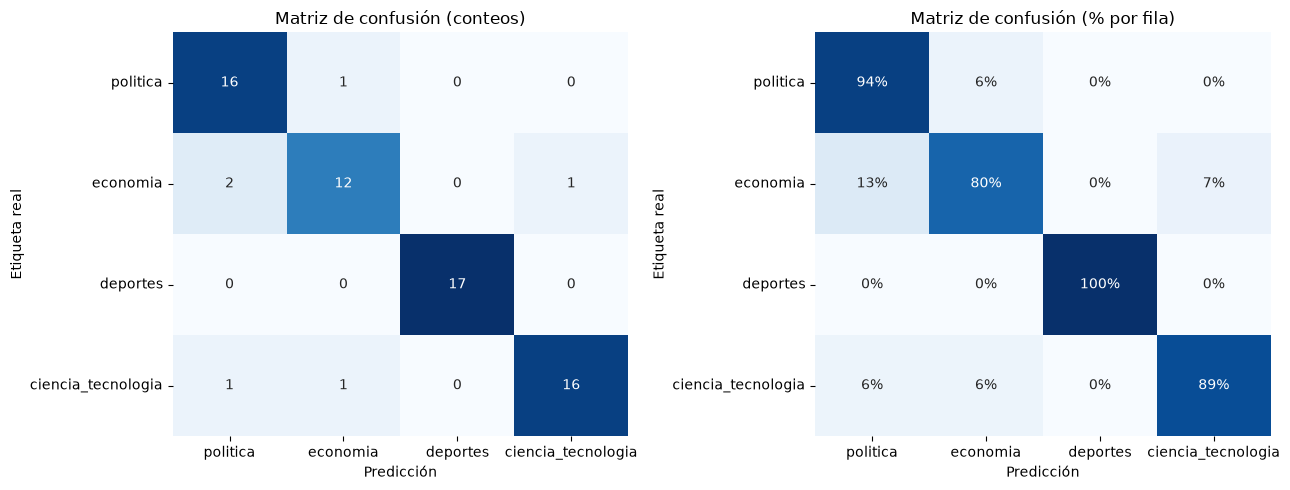

F1 macro por medio: {'El Comercio': 0.849, 'La Republica': 0.968}

Errores del modelo en test:


,medio,etiqueta,pred_ft,titular
11,La Republica,economia,politica,Feriado por visita del papa León XIV: ministro de Trabajo espera pronunciamiento del Vaticano antes de anu...
16,El Comercio,ciencia_tecnologia,economia,El Niño en Perú: no está operativo ninguno de los 18 sistemas de alertas tempranas previstos desde 2017
23,El Comercio,economia,ciencia_tecnologia,Wall Street abre mixto arrastrado por los fabricantes de semiconductores
25,El Comercio,politica,economia,Viceministra de Minas: “Estamos estableciendo un plazo de 18 meses y no abrimos la puerta a una nueva ampl...
34,El Comercio,ciencia_tecnologia,politica,Fenómeno El Niño Costero: ¿cuáles pueden ser las consecuencias para el Perú?
65,El Comercio,economia,politica,Mincetur designa a Roxana Barrantes como nuevo miembro del Consejo Directivo de Indecopi


In [9]:
clasificador = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer, device="cpu")
inicio = time.perf_counter()
test["pred_ft"] = [clasificador(t)[0]["label"] for t in test["titular"]]     # de a uno, como en el dashboard
latencia_ft = (time.perf_counter() - inicio) / len(test)

acc_ft = accuracy_score(test["etiqueta"], test["pred_ft"])
f1_ft = f1_score(test["etiqueta"], test["pred_ft"], average="macro")
print(f"FINE-TUNED (test, {len(test)} titulares) | accuracy = {acc_ft:.3f} | F1 macro = {f1_ft:.3f} "
      f"| latencia = {latencia_ft * 1000:.0f} ms por titular\n")
print(classification_report(test["etiqueta"], test["pred_ft"], labels=CATEGORIAS, digits=3))

cm = confusion_matrix(test["etiqueta"], test["pred_ft"], labels=CATEGORIAS)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=CATEGORIAS, yticklabels=CATEGORIAS)
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=CATEGORIAS, yticklabels=CATEGORIAS)
axes[0].set(title="Matriz de confusión (conteos)", xlabel="Predicción", ylabel="Etiqueta real")
axes[1].set(title="Matriz de confusión (% por fila)", xlabel="Predicción", ylabel="Etiqueta real")
plt.tight_layout()
plt.show()

f1_por_medio = {medio: f1_score(g["etiqueta"], g["pred_ft"], average="macro") for medio, g in test.groupby("medio")}
print("F1 macro por medio:", {m: round(v, 3) for m, v in f1_por_medio.items()})
print("\nErrores del modelo en test:")
display(test.loc[test["pred_ft"] != test["etiqueta"], ["medio", "etiqueta", "pred_ft", "titular"]])

### Reflexión por categoría

| Categoría | F1 test | Lectura |
|---|---|---|
| deportes | **1,000** (mejor) | Vocabulario cerrado y exclusivo |
| ciencia_tecnologia | 0,914 | Falla solo con El Niño |
| politica | 0,889 | Alta cobertura, menor precisión: absorbe errores ajenos |
| economia | **0,828** (peor) | Comparte actores con política |

* **Deportes es la mejor (F1 = 1,000)** porque su vocabulario no se cruza con ningún otro tema: nombres de clubes y
  torneos (*Alianza Lima*, *LaLiga*, *Clausura*) y titulares de servicio con fórmula fija (*"fecha, hora y canal"*,
  *"dónde ver"*). También es la única categoría sin un solo desacuerdo entre el LLM y la etiqueta editorial.
* **Economía es la peor (F1 = 0,828, recall 0,80)** por una causa temática: en Perú la economía se cuenta a través
  de actores del Estado. *"Mincetur designa a Roxana Barrantes…"* o *"Feriado por visita del papa León XIV: ministro
  de Trabajo…"* tienen como sujeto a un ministerio o un ministro, igual que una noticia política, y el modelo solo ve
  esas 15 palabras. La otra falla va hacia tecnología: en *"Wall Street abre mixto arrastrado por los fabricantes de
  semiconductores"*, la palabra *semiconductores* pesa más que *Wall Street*. El LLM tropieza en la misma frontera:
  13 de sus 19 desacuerdos con la etiqueta editorial están entre economía y política.
* **Política (F1 = 0,889)** tiene la cobertura más alta (recall 0,94) pero la precisión más baja (0,84): recibe 3
  de los 6 errores, dos titulares con un ministerio o un ministro como sujeto y uno de El Niño.
* **Ciencia y tecnología (F1 = 0,914)** falla solo con El Niño. Las dos notas mal clasificadas (*"El Niño en Perú:
  no está operativo ninguno de los 18 sistemas de alertas…"* y *"Fenómeno El Niño Costero: ¿cuáles pueden ser las
  consecuencias para el Perú?"*) son de clima, pero en train "El Niño" aparece en 4 titulares de economía, 1 de
  política y solo 1 de ciencia. El modelo aprendió la asociación más frecuente: es un sesgo de los datos de la
  quincena, no del idioma.
* **Por medio:** 5 de los 6 errores son de El Comercio (F1 0,849 contra 0,968 de La República). Sus secciones son
  más amplias (`tecnologia` incluye ecología y clima; `economia`, nombramientos en organismos del Estado), y sus
  titulares son más cortos (mediana de 95 caracteres contra 106), así que dan menos contexto para decidir.
* **La auditoría muestra el mismo tipo de frontera.** El único desacuerdo humano-LLM (caso 11, *"Noruega estudia
  prohibir temporalmente las gafas inteligentes"*) es regulación estatal sobre un objeto tecnológico: el LLM y la
  sección editorial eligieron tecnología; quien audita, política. Ninguna lectura es claramente incorrecta. En
  estos casos la etiqueta "verdadera" depende del criterio, no del texto.

## 8. Comparativa y decisión

Para comparar en igualdad de condiciones, además de la métrica de cada enfoque en su propio conjunto, se calcula el
F1 de **todos** sobre los mismos 40 titulares del zero-shot.

In [10]:
test_40 = test[test["url"].isin(muestra_40["url"])].merge(muestra_40[["url", "pred_zs"]], on="url")


def fila(enfoque, evaluado, y_real, y_pred, pred_40, latencia, costo, internet):
    return {"enfoque": enfoque, "evaluado sobre": evaluado,
            "accuracy": accuracy_score(y_real, y_pred), "F1 macro": f1_score(y_real, y_pred, average="macro"),
            "F1 macro (40 comunes)": f1_score(test_40["etiqueta"], test_40[pred_40], average="macro"),
            "latencia (ms/titular)": round(latencia * 1000), "costo": costo, "internet": internet}


comparativa = pd.DataFrame([
    fila("Zero-shot (BETO-XNLI)", "40 titulares del test", muestra_40["etiqueta"], muestra_40["pred_zs"],
         "pred_zs", latencia_zs, "gratis (CPU local)", "solo para descargar el modelo"),
    fila(f"LLM débil ({df['modelo_llm'].mode()[0]})", f"test ({len(test)})", test["etiqueta"], test["etiqueta_llm"],
         "etiqueta_llm", latencia_llm, "API por llamada (plan gratuito con cuota)", "sí, en cada predicción"),
    fila("DistilBERT fine-tuned (etiqueta editorial)", f"test ({len(test)})", test["etiqueta"], test["pred_ft"],
         "pred_ft", latencia_ft, "gratis (CPU local)", "solo para descargar el modelo"),
    fila("DistilBERT fine-tuned (etiqueta LLM)", f"test ({len(test)})", test["etiqueta"], test["pred_ft_llm"],
         "pred_ft_llm", latencia_ft, "gratis (CPU local) + etiquetado con API", "solo para descargar el modelo"),
]).round(3)
display(comparativa)

metricas = {
    "f1_macro_test": round(f1_ft, 3), "accuracy_test": round(acc_ft, 3), "n_test": len(test),
    "f1_macro_por_medio": {m: round(v, 3) for m, v in f1_por_medio.items()},
    "f1_macro_zero_shot": round(f1_zs, 3), "acuerdo_llm_humano": acuerdo_llm_humano, "n_auditoria": 20, "extraccion_verificada": extraccion_ok,
    "acuerdo_llm_editorial": round(acuerdo_editorial, 3), "modelo_base": MODELO_BASE,
    "modelo_llm": df["modelo_llm"].mode()[0], "fecha_entrenamiento": date.today().isoformat(),
}
(MODELO / "metricas.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Resultados Test: F1 Macro: {f1_ft:.3f} | Zero-shot: {f1_zs:.3f} | Acuerdo LLM-Humano: {acuerdo_llm_humano}/20")

,enfoque,evaluado sobre,accuracy,F1 macro,F1 macro (40 comunes),latencia (ms/titular),costo,internet
0,Zero-shot (BETO-XNLI),40 titulares del test,0.675,0.640,0.640,194,gratis (CPU local),solo para descargar el modelo
1,LLM débil (gemini-3.8-flash),test (67),0.910,0.909,0.876,1461,API por llamada (plan gratuito con cuota),"sí, en cada predicción"
2,DistilBERT fine-tuned (etiqueta editorial),test (67),0.910,0.908,0.873,23,gratis (CPU local),solo para descargar el modelo
3,DistilBERT fine-tuned (etiqueta LLM),test (67),0.851,0.848,0.826,23,gratis (CPU local) + etiquetado con API,solo para descargar el modelo


Resultados Test: F1 Macro: 0.908 | Zero-shot: 0.640 | Acuerdo LLM-Humano: 19/20


### Decisión para un entorno real

**Modelo elegido: DistilBERT ajustado con la etiqueta editorial.**

* **Calidad equivalente al LLM.** F1 macro de 0,908 contra 0,909 en test, y 0,873 contra 0,876 en los 40 titulares
  comunes. Con 67 titulares de test, un acierto más o menos mueve el F1 cerca de 1,5 puntos, así que esa diferencia
  es ruido. Además, el LLM leyó titular y bajada, y el modelo ajustado solo el titular.
* **60 veces más rápido.** 23 ms por titular en CPU local contra 1.461 ms del LLM por API.
* **Gratis, sin internet y reproducible.** No consume cuota de API, funciona sin conexión una vez descargado y
  responde siempre lo mismo ante el mismo titular. El alias `gemini-flash-latest`, en cambio, puede cambiar de
  modelo sin aviso, y en este mismo etiquetado 5 de las noticias las respondió el modelo de respaldo.
* **El zero-shot queda descartado** (F1 0,640): sin ejemplos no aprende el criterio editorial, y en ciencia y
  tecnología acierta solo 2 de 10.

**El LLM sirve mejor como etiquetador que como clasificador en línea.** El DistilBERT entrenado solo con etiquetas
del LLM llega a F1 0,848, 6 puntos menos que con la etiqueta editorial, pero sin necesitar la sección del diario.
Eso lo hace útil para un medio que no publica secciones o para agregar una categoría nueva. Parte de esa diferencia
no son errores sino criterios distintos (la frontera economía–política), porque se mide contra la etiqueta editorial.

**Esquema propuesto:** el modelo ajustado clasifica todo; si su probabilidad máxima es menor a 0,6 (el mismo umbral
de aviso de la app), el titular pasa al LLM o a revisión humana. Así se paga el costo del LLM solo en los casos
ambiguos.

**Riesgos a vigilar:**

* **Deriva temporal.** El modelo aprendió de dos semanas de octubre de 2026 (León XIV, El Niño Costero, elecciones).
  El caso El Niño muestra cómo un tema de la quincena sesga las asociaciones; hay que reentrenar periódicamente.
* **Test pequeño.** 67 titulares dan una estimación con un margen amplio; para producción se necesita un test mayor.
* **La confianza del LLM no está calibrada.** En el tramo de 0,8 a 0,9 declara 0,88 de confianza media pero acierta
  el 74,5 %, así que no sirve como umbral directo sin recalibrarla.